<a href="https://colab.research.google.com/github/jyryu3161/chembigdata/blob/main/lec11_BBBP_decision_tree_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BBBP 예측: 의사결정나무와 랜덤 포레스트

**학습 목표**: 분자 구조를 Morgan fingerprint로 표현하고, 의사결정나무와 랜덤 포레스트를 학습하여 비교합니다. 마지막으로 각 모델의 BBB 투과 **예측 확률**을 제출 파일로 저장합니다.

- `target=1`: BBB 투과, `target=0`: BBB 비투과
- Colab에서 **런타임 → 모두 실행** 또는 위에서부터 셀을 차례로 실행하세요.
- lec10과 같은 `train.csv`, `val.csv`, `test.csv`, `sample_submission.csv`가 필요합니다.
- 모델의 설정을 몇 가지 바꾸어 보고 내부 검증 결과를 비교합니다.

## 0. 환경 준비

Colab에서 RDKit을 설치합니다. 이미 설치되어 있어도 실행해도 됩니다.

In [ ]:
!pip install -q rdkit

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, matthews_corrcoef, confusion_matrix

RDLogger.DisableLog("rdApp.*")
SEED = 42  # 같은 데이터와 설정에서 결과를 다시 재현하기 위한 숫자

## 1. 데이터 불러오기

아래 셀에서 파일 선택 창이 나타나면 네 파일을 한꺼번에 업로드합니다. 이미 Colab의 현재 폴더에 있다면 업로드를 건너뜁니다.

`train`에만 정답 `target`이 있습니다. 대회의 `val`과 `test`는 정답이 없으므로, 모델 비교에는 **train에서 따로 나눈 내부 검증 데이터**를 사용합니다.

In [ ]:
file_names = ["train.csv", "val.csv", "test.csv", "sample_submission.csv"]
missing = [name for name in file_names if not os.path.exists(name)]

if missing:
    from google.colab import files
    print("다음 파일을 업로드하세요:", missing)
    files.upload()

train = pd.read_csv("train.csv")
val = pd.read_csv("val.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

print("train:", train.shape, "val:", val.shape, "test:", test.shape)
print("제출 양식:", sample_sub.shape)
display(train.head())
print("정답별 개수")
print(train["target"].value_counts().sort_index())

train: (1421, 3) val: (203, 2) test: (406, 2)
제출 양식: (609, 2)


,sample_id,SMILES,target
0,train_0001,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,0
1,train_0002,COC(=O)[C@@]1(O)CC[C@H]2C3CCC(=O)C4C(=O)C=CC4(...,1
2,train_0003,CN(C)CCc1ccccn1,1
3,train_0004,CC(C)NCC(O)COc1ccc(CC(N)=O)cc1,0
4,train_0005,O=C(Nc1ccc(O)cc1)C(Cl)(Cl)Cl,1


정답별 개수
target
0     341
1    1080
Name: count, dtype: int64


## 2. SMILES를 숫자로 바꾸기

SMILES는 분자 구조를 나타내는 문자열입니다. 모델에 바로 넣을 수 없으므로 RDKit으로 **Morgan fingerprint**를 만듭니다. 각 분자는 부분구조의 유무를 나타내는 2048개의 0과 1로 표현됩니다. lec10과 같은 반경 2를 사용합니다.

트리 모델은 숫자의 크기를 비교해 분할하므로 별도의 표준화가 필요하지 않습니다.

In [ ]:
# 읽을 수 없는 SMILES는 조용히 버리지 않고, 어느 파일의 몇 번째 행인지 알려줍니다.
for name, data in [("train", train), ("val", val), ("test", test)]:
    data["mol"] = data["SMILES"].apply(Chem.MolFromSmiles)
    bad_rows = data.index[data["mol"].isna()].tolist()
    print(f"{name}: 변환 실패 {len(bad_rows)}개")
    if bad_rows:
        raise ValueError(f"{name}의 SMILES를 확인하세요. 데이터 행 번호: {bad_rows[:10]}")

train: 변환 실패 0개
val: 변환 실패 0개
test: 변환 실패 0개


In [ ]:
# 모든 데이터에 같은 방법으로 fingerprint를 만듭니다.
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def make_fingerprints(molecules):
    fingerprints = []
    for mol in molecules:
        fingerprints.append(generator.GetFingerprintAsNumPy(mol))
    return np.array(fingerprints)

X = make_fingerprints(train["mol"])
X_val = make_fingerprints(val["mol"])
X_test = make_fingerprints(test["mol"])
y = train["target"].to_numpy()

print("train fingerprint 크기:", X.shape)
print("첫 분자의 앞쪽 20개 비트:", X[0, :20])

train fingerprint 크기: (1421, 2048)
첫 분자의 앞쪽 20개 비트: [0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


## 3. 내부 학습 데이터와 검증 데이터 나누기

대회 `val.csv`와 구별하기 위해, 여기서 나누는 것을 **내부 검증 데이터**라고 부릅니다. `stratify=y`는 두 그룹의 0과 1 비율을 비슷하게 유지합니다. 두 모델에 같은 데이터를 사용해 공정하게 비교합니다.

무작위 분할에서는 비슷한 구조의 화합물이 양쪽에 들어갈 수 있으므로 실제 새로운 구조에 대한 성능은 다를 수 있습니다.

In [ ]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("내부 학습:", len(y_fit), "개 / 내부 검증:", len(y_valid), "개")

# 학습 데이터와 검증 데이터의 0과 1의 비율을 확인합니다.
counts = pd.DataFrame({
    "내부 학습": pd.Series(y_fit).value_counts(),
    "내부 검증": pd.Series(y_valid).value_counts()
}).sort_index()
counts.index.name = "target"
ratio = (counts / counts.sum() * 100).round(1)

display(counts.astype(str) + "개 (" + ratio.astype(str) + "%)")

내부 학습: 1136 개 / 내부 검증: 285 개


,내부 학습,내부 검증
target,,
0,273개 (24.0%),68개 (23.9%)
1,863개 (76.0%),217개 (76.1%)


## 4. 의사결정나무 (Decision Tree)

의사결정나무는 특성에 대해 질문을 반복하며 데이터를 나눕니다. 여기서는 fingerprint의 각 비트가 분할 질문이 됩니다. `criterion="gini"`는 각 그룹에 0과 1이 얼마나 섞여 있는지 나타내는 **지니 불순도**를 사용합니다. 모델은 분할 후 불순도가 줄어드는 질문을 찾습니다.

나무가 너무 깊어지면 학습 데이터에 과하게 맞을 수 있습니다. 여기서는 `max_depth=5`로 깊이를 제한합니다. 예시 설정이며 최적값이라는 뜻은 아닙니다.

In [ ]:
# 학습 데이터를 사용해 의사결정나무를 만듭니다.
tree = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=SEED)
tree.fit(X_fit, y_fit)

# predict_proba의 두 번째 열은 target=1일 확률입니다.
tree_prob = tree.predict_proba(X_valid)[:, 1]
tree_pred = (tree_prob >= 0.5).astype(int)
print("Decision Tree Accuracy:", round(accuracy_score(y_valid, tree_pred), 3))
print("Decision Tree ROC-AUC:", round(roc_auc_score(y_valid, tree_prob), 3))
print("Decision Tree MCC:", round(matthews_corrcoef(y_valid, tree_pred), 3))

Decision Tree Accuracy: 0.856
Decision Tree ROC-AUC: 0.813
Decision Tree MCC: 0.569


아래 그림은 학습된 나무를 보여줍니다. 예를 들어 `X[123] <= 0.5`는 123번 fingerprint 비트가 0인지 묻는 질문입니다.
- `gini`는 해당 노드의 불순도, `samples`는 학습에 사용된 분자의 개수입니다.
- `value`는 그 노드에 들어온 학습 분자들의 정답 개수입니다. (value = [target 0인 분자 수, target 1인 분자 수])

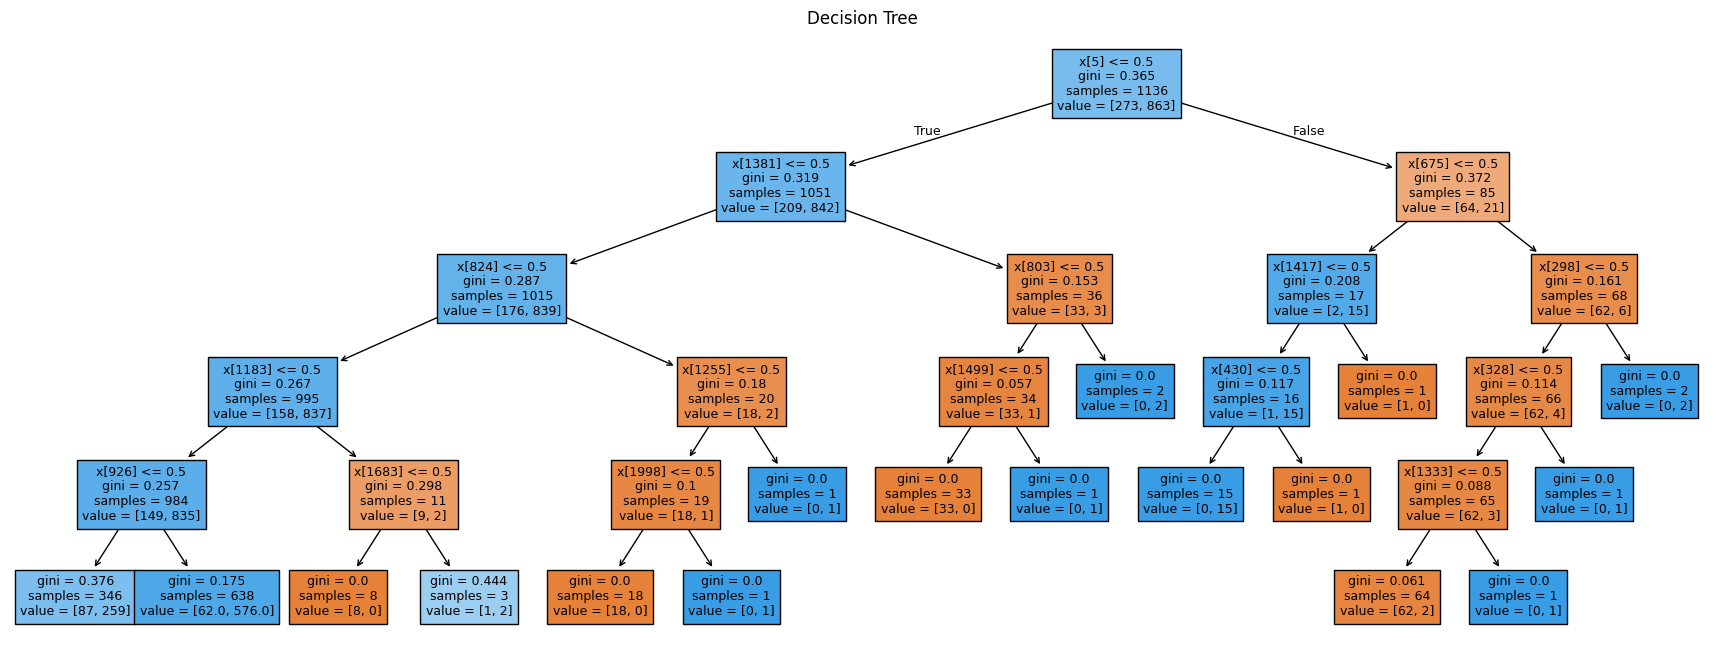

In [ ]:
plt.figure(figsize=(22, 8))
plot_tree(tree, max_depth=5, filled=True, fontsize=9)
plt.title("Decision Tree")
plt.show()

## 5. 랜덤 포레스트 (Random Forest)

랜덤 포레스트는 여러 의사결정나무의 결과를 결합합니다. 각 나무는 학습 데이터에서 **복원 추출**한 표본을 사용하고, 각 분할에서 일부 특성을 무작위로 살펴봅니다. 여러 나무의 예측 확률을 평균하면 한 나무에 의존하는 정도를 줄일 수 있습니다.

`n_estimators=100`은 나무 100개를 뜻합니다. 랜덤 포레스트도 과적합이 완전히 사라지는 것은 아닙니다.

In [ ]:
forest = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
forest.fit(X_fit, y_fit)

forest_prob = forest.predict_proba(X_valid)[:, 1]
forest_pred = (forest_prob >= 0.5).astype(int)
print("Random Forest Accuracy:", round(accuracy_score(y_valid, forest_pred), 3))
print("Random Forest ROC-AUC:", round(roc_auc_score(y_valid, forest_prob), 3))
print("Random Forest MCC:", round(matthews_corrcoef(y_valid, forest_pred), 3))

Random Forest Accuracy: 0.881
Random Forest ROC-AUC: 0.908
Random Forest MCC: 0.65


## 6. 두 모델 비교

- **Accuracy**: 임계값 0.5로 분류했을 때 맞힌 비율입니다. 클래스가 불균형하면 이것만으로 판단하기 어렵습니다.
- **ROC-AUC**: 1인 분자에 더 높은 점수를 주는 경향을 나타냅니다. 0/1 분류값이 아닌 **예측 확률**로 계산합니다.
- **MCC**: 클래스 불균형 상황에서 모델이 두 클래스(0과 1)를 얼마나 골고루 잘 맞혔는지 보여주는 평가지표입니다. "실제 정답과 모델의 예측값 사이의 상관관계"를 나타내며, -1부터 +1 사이의 값을 가집니다.

여기서는 한 번의 내부 검증 결과입니다. 점수 차이가 작다면 분할에 따라 결과가 달라질 수 있습니다.

,Model,Accuracy,ROC-AUC,MCC
0,Decision Tree,0.856,0.813,0.569
1,Random Forest,0.881,0.908,0.650


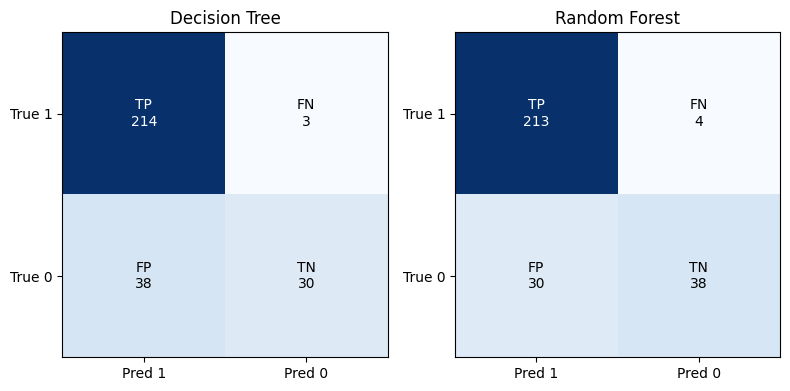

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [accuracy_score(y_valid, tree_pred), accuracy_score(y_valid, forest_pred)],
    "ROC-AUC": [roc_auc_score(y_valid, tree_prob), roc_auc_score(y_valid, forest_prob)],
    "MCC": [matthews_corrcoef(y_valid, tree_pred), matthews_corrcoef(y_valid, forest_pred)]
})
display(comparison.round(3))

# 혼동행렬: 윗줄이 실제 Positive, 아랫줄이 실제 Negative 입니다.
names = [["TP", "FN"], ["FP", "TN"]]

def plot_confusion(y_true, y_pred, ax, title):
    matrix = confusion_matrix(y_true, y_pred, labels=[1, 0])
    ax.imshow(matrix, cmap="Blues")

    for i in range(2):
        for j in range(2):
            val = matrix[i, j]
            text_color = "white" if val > matrix.max() / 2 else "black"
            ax.text(j, i, f"{names[i][j]}\n{val}", ha="center", va="center", color=text_color)

    ax.set_xticks([0, 1], ["Pred 1", "Pred 0"])
    ax.set_yticks([0, 1], ["True 1", "True 0"])
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
plot_confusion(y_valid, tree_pred, axes[0], "Decision Tree")
plot_confusion(y_valid, forest_pred, axes[1], "Random Forest")
plt.tight_layout()
plt.show()

## 7. 하이퍼파라미터 바꾸어 보기

**하이퍼파라미터**는 학습 전에 사람이 정하는 모델의 설정입니다. 한 번에 한 설정만 바꾸면 결과가 어떻게 달라지는지 살펴보기 쉽습니다. 아래 예시는 정답을 찾는 자동 탐색이 아니라, 값을 직접 바꾸어 보는 실습입니다.

### 7-1. 의사결정나무의 깊이

`max_depth`는 나무가 질문을 이어갈 수 있는 최대 깊이입니다. 작은 값은 단순한 규칙을 만들지만 중요한 패턴을 놓칠 수 있습니다. 큰 값은 복잡한 규칙을 배울 수 있지만 학습 데이터에 지나치게 맞을 수 있습니다. 앞에서 사용한 깊이 5와 깊이 2, 10을 비교합니다.

In [ ]:
# 얕은 나무: 최대 깊이 2
tree_depth2 = DecisionTreeClassifier(max_depth=2, random_state=SEED)
tree_depth2.fit(X_fit, y_fit)
tree_depth2_prob = tree_depth2.predict_proba(X_valid)[:, 1]

# 깊은 나무: 최대 깊이 10
tree_depth10 = DecisionTreeClassifier(max_depth=10, random_state=SEED)
tree_depth10.fit(X_fit, y_fit)
tree_depth10_prob = tree_depth10.predict_proba(X_valid)[:, 1]

# 학습 정확도와 내부 검증 결과를 나란히 확인합니다.
tree_results = pd.DataFrame({
    "max_depth": [2, 5, 10],
    "학습 Accuracy": [tree_depth2.score(X_fit, y_fit), tree.score(X_fit, y_fit),
                      tree_depth10.score(X_fit, y_fit)],
    "학습 MCC": [matthews_corrcoef(y_fit, tree_depth2.predict(X_fit)),
                 matthews_corrcoef(y_fit, tree.predict(X_fit)),
                 matthews_corrcoef(y_fit, tree_depth10.predict(X_fit))],
    "검증 Accuracy": [accuracy_score(y_valid, tree_depth2_prob >= 0.5),
                      accuracy_score(y_valid, tree_prob >= 0.5),
                      accuracy_score(y_valid, tree_depth10_prob >= 0.5)],
    "검증 ROC-AUC": [roc_auc_score(y_valid, tree_depth2_prob),
                     roc_auc_score(y_valid, tree_prob),
                     roc_auc_score(y_valid, tree_depth10_prob)],
    "검증 MCC": [matthews_corrcoef(y_valid, tree_depth2_prob >= 0.5),
                 matthews_corrcoef(y_valid, tree_prob >= 0.5),
                 matthews_corrcoef(y_valid, tree_depth10_prob >= 0.5)]
})
display(tree_results.round(3))

,max_depth,학습 Accuracy,학습 MCC,검증 Accuracy,검증 ROC-AUC,검증 MCC
0,2,0.835,0.500,0.832,0.654,0.480
1,5,0.866,0.612,0.856,0.813,0.569
2,10,0.915,0.759,0.860,0.751,0.580


학습 정확도는 높은데 검증 점수가 낮아지면 과적합을 의심할 수 있습니다. 단, 한 번의 분할만으로 단정할 수는 없습니다. 다른 깊이도 직접 바꾸어 확인해 보세요.

### 7-2. 랜덤 포레스트의 나무 수와 깊이

- `n_estimators`: 나무의 개수입니다. 나무를 늘리면 결과가 안정되는 경향이 있지만 학습 시간이 늘어납니다. 점수가 반드시 올라가지는 않습니다.
- `max_depth`: 각 나무의 최대 깊이입니다. `None`은 깊이에 제한을 따로 두지 않는다는 뜻이며, 다른 정지 조건에 따라 성장이 멈춥니다.

기본 실습의 **100개, 깊이 제한 없음**을 기준으로, 나무 수만 바꾼 경우(30개)와 깊이만 제한한 경우(5, 10), 그리고 둘 다 바꾼 경우(30개 + 깊이 5)를 함께 비교합니다.

In [ ]:
# 나무 수만 변경: 100개 → 30개
forest_30 = RandomForestClassifier(n_estimators=30, random_state=SEED, n_jobs=-1)
forest_30.fit(X_fit, y_fit)
forest_30_prob = forest_30.predict_proba(X_valid)[:, 1]

# 깊이만 변경: 제한 없음 → 5 (나무 수는 100개 유지)
forest_depth5 = RandomForestClassifier(
    n_estimators=100, max_depth=5, random_state=SEED, n_jobs=-1
)
forest_depth5.fit(X_fit, y_fit)
forest_depth5_prob = forest_depth5.predict_proba(X_valid)[:, 1]

# 깊이만 변경: 제한 없음 → 10 (나무 수는 100개 유지)
forest_depth10 = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1
)
forest_depth10.fit(X_fit, y_fit)
forest_depth10_prob = forest_depth10.predict_proba(X_valid)[:, 1]

# 나무 수와 깊이를 함께 변경: 30개 + 깊이 5
forest_30_depth5 = RandomForestClassifier(
    n_estimators=30, max_depth=5, random_state=SEED, n_jobs=-1
)
forest_30_depth5.fit(X_fit, y_fit)
forest_30_depth5_prob = forest_30_depth5.predict_proba(X_valid)[:, 1]

forest_probs = {
    "나무 30개, 깊이 제한 없음": (forest_30, forest_30_prob),
    "나무 100개, 깊이 제한 없음": (forest, forest_prob),
    "나무 30개, 깊이 5": (forest_30_depth5, forest_30_depth5_prob),
    "나무 100개, 깊이 5": (forest_depth5, forest_depth5_prob),
    "나무 100개, 깊이 10": (forest_depth10, forest_depth10_prob),
}

forest_results = pd.DataFrame({
    "설정": list(forest_probs),
    "학습 Accuracy": [model.score(X_fit, y_fit) for model, _ in forest_probs.values()],
    "학습 MCC": [matthews_corrcoef(y_fit, model.predict(X_fit)) for model, _ in forest_probs.values()],
    "검증 Accuracy": [accuracy_score(y_valid, prob >= 0.5) for _, prob in forest_probs.values()],
    "검증 ROC-AUC": [roc_auc_score(y_valid, prob) for _, prob in forest_probs.values()],
    "검증 MCC": [matthews_corrcoef(y_valid, prob >= 0.5) for _, prob in forest_probs.values()]
})
display(forest_results.round(3))

,설정,학습 Accuracy,학습 MCC,검증 Accuracy,검증 ROC-AUC,검증 MCC
0,"나무 30개, 깊이 제한 없음",0.993,0.981,0.877,0.906,0.638
1,"나무 100개, 깊이 제한 없음",0.994,0.983,0.881,0.908,0.650
2,"나무 30개, 깊이 5",0.841,0.522,0.825,0.873,0.455
3,"나무 100개, 깊이 5",0.843,0.531,0.825,0.875,0.455
4,"나무 100개, 깊이 10",0.875,0.641,0.860,0.904,0.583


학습이 끝난 나무는 `get_depth()`로 깊이를 확인할 수 있습니다.

In [ ]:
# 깊이 제한이 없던 포레스트의 나무 100개가 각각 얼마나 깊어졌는지 확인합니다.
depths = [estimator.get_depth() for estimator in forest.estimators_]
print("나무 100개, 깊이 제한 없음")
print("  최소", min(depths), "/ 최대", max(depths))

나무 100개, 깊이 제한 없음
  최소 32 / 최대 69


## 8. 전체 train으로 다시 학습하고 제출 파일 만들기

비교가 끝나면 내부 검증에 사용했던 데이터까지 포함하여 **전체 train**으로 각 모델을 다시 학습합니다. 대회 `val`과 `test`의 정답은 학습에 사용하지 않습니다.

제출할 값은 0/1이 아닌 **BBB 투과 확률**입니다. 두 파일 모두 기존 제출 양식의 `sample_id` 순서를 따릅니다. 제출 시 원하는 모델의 파일을 선택하세요.

In [ ]:
# 제출할 설정을 선택합니다. 예: tree_depth2 또는 forest_depth5
# 기본 설정을 사용하려면 아래 두 줄을 그대로 두세요.
final_tree = tree
final_forest = forest

# 선택한 설정을 전체 train 데이터로 다시 학습합니다.
final_tree.fit(X, y)
final_forest.fit(X, y)

tree_val_prob = final_tree.predict_proba(X_val)[:, 1]
tree_test_prob = final_tree.predict_proba(X_test)[:, 1]
forest_val_prob = final_forest.predict_proba(X_val)[:, 1]
forest_test_prob = final_forest.predict_proba(X_test)[:, 1]

In [ ]:
# 예측값을 합친 뒤 제출 양식의 sample_id 순서에 맞춥니다.
def save_submission(val_prob, test_prob, filename):
    val_pred = pd.DataFrame({"sample_id": val["sample_id"], "prediction": val_prob})
    test_pred = pd.DataFrame({"sample_id": test["sample_id"], "prediction": test_prob})
    all_pred = pd.concat([val_pred, test_pred], ignore_index=True)

    submission = sample_sub[["sample_id"]].merge(
        all_pred, on="sample_id", how="left", validate="one_to_one"
    )
    assert len(submission) == len(sample_sub)
    assert len(all_pred) == len(sample_sub)  # 양식 밖의 ID도 없어야 합니다.
    assert submission["prediction"].notna().all()
    assert submission["prediction"].between(0, 1).all()
    submission.to_csv(filename, index=False)
    print(filename, "저장 완료:", len(submission), "행")
    display(submission.head())

save_submission(tree_val_prob, tree_test_prob, "submission_tree.csv")
save_submission(forest_val_prob, forest_test_prob, "submission_forest.csv")

submission_tree.csv 저장 완료: 609 행


,sample_id,prediction
0,val_001,0.742317
1,val_002,0.742317
2,val_003,0.742317
3,val_004,0.908075
4,val_005,0.908075


submission_forest.csv 저장 완료: 609 행


,sample_id,prediction
0,val_001,0.79
1,val_002,0.98
2,val_003,0.94
3,val_004,0.94
4,val_005,0.79


In [ ]:
# Colab에서 두 파일을 다운로드합니다.
try:
    from google.colab import files
    files.download("submission_tree.csv")
    files.download("submission_forest.csv")
except ImportError:
    print("두 제출 파일이 현재 폴더에 저장되어 있습니다.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. 확인 문제

1. 의사결정나무는 지니 불순도를 사용하여 어떤 분할을 선택하나요?
2. `max_depth`를 너무 크게 설정하면 어떤 문제가 생길 수 있나요?
3. 랜덤 포레스트의 나무들은 학습 데이터와 분할 후보를 어떻게 선택하나요?
4. 내부 검증 데이터와 대회 `val.csv`의 차이는 무엇인가요?
5. 나무의 깊이를 늘렸을 때 학습과 검증 점수의 차이는 어떻게 변했나요?
6. 제출 파일에 0/1 대신 예측 확률을 저장하는 이유는 무엇인가요?

**제출:** 비교 결과를 확인한 뒤, 안내받은 방식에 따라 두 제출 파일 중 선택하여 제출합니다.